# H2O Regression Pipeline for Flight Time Prediction

This notebook implements a regression pipeline using H2O AutoML to predict actual departure and arrival times for flights. Unlike the classification version that predicts delays, this version focuses on predicting the exact timing of flights.

## Key Differences from Classification Pipeline:
- **Target Variables**: Actual departure time (ATD) and actual arrival time (ATA)
- **Problem Type**: Multi-target regression instead of binary classification
- **Evaluation Metrics**: MAE, RMSE, R² instead of AUC, F1-score
- **Business Value**: Precise time predictions for operational planning

In [1]:
# Import required libraries
import subprocess
import sys
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="15G", nthreads=-1, enable_assertions=False,
    jvm_custom_args=["-Dai.h2o.gpu.enabled=true"]
)

print("H2O initialized successfully!")
# Check if GPU is available
cluster_info = h2o.cluster().get_status()
print("Cluster info:", cluster_info)

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /home/kristsey/.local/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmp7eh8o7s6
  JVM stdout: /tmp/tmp7eh8o7s6/h2o_kristsey_started_from_python.out
  JVM stderr: /tmp/tmp7eh8o7s6/h2o_kristsey_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,00 secs
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,6 months and 1 day
H2O_cluster_name:,H2O_from_python_kristsey_atlx60
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,14.98 Gb
H2O_cluster_total_cores:,24
H2O_cluster_allowed_cores:,24
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!
Cluster info: H2O_cluster_uptime    H2O_cluster_timezone    H2O_data_parsing_timezone    H2O_cluster_version    H2O_cluster_version_age    H2O_cluster_name                 H2O_cluster_total_nodes    H2O_cluster_free_memory    H2O_cluster_total_cores    H2O_cluster_allowed_cores    H2O_cluster_status    H2O_connection_url      H2O_connection_proxy           H2O_internal_security    Python_version
--------------------  ----------------------  ---------------------------  ---------------------  -------------------------  -------------------------------  -------------------------  -------------------------  -------------------------  ---------------------------  --------------------  ----------------------  -----------------------------  -----------------------  ----------------
00 secs               Europe/Oslo             UTC                          3.46.0.7               6 months and 1 day         H2O_from_python_kristsey_atlx60  1                         

In [2]:
# Load the historical flights dataset
print("Loading historical flights dataset...")
import os
data_path = os.path.join("..", "data", "flight_weather_features.csv")

# Load data
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())

Loading historical flights dataset...
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
  flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
0     WF149         HOV            

In [ ]:
# Data Preprocessing for Regression
print("Starting data preprocessing for regression...")

import sys
import os

print(len(df))

# Add the parent directory to the Python path so we can import from src
parent_dir = os.path.dirname(os.path.dirname(os.path.abspath("avinorhackathon")))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

print(sys.path)

# Now we can import from src
from src.preprocessing import DataPreprocessor

data_preprocessor = DataPreprocessor()
df_processed = data_preprocessor.process_hist_flights(df)
print(df_processed["flight_id"].nunique())

print(len(df_processed))

# Remove rows with missing actual departure or arrival times
df_processed = df_processed.dropna(subset=["atd", "ata"])
print(f"Dataset shape after removing missing actual times: {df_processed.shape}")

# Ensure datetime dtypes
for _c in ["std", "sta", "atd", "ata"]:
    df_processed[_c] = pd.to_datetime(df_processed[_c], errors="coerce")

# Calculate scheduled duration in minutes (convert timedelta to total minutes)
df_processed["scheduled_duration"] = (
    (df_processed["sta"] - df_processed["std"]).dt.total_seconds() / 60
)

# --- FIX OVERSHOOTING SCHEDULED ARRIVAL DATES ---
# Threshold (minutes) above which we assume the date part of 'sta' is wrong
MAX_SCHED_FOR_FIX = 360  # 6 hours (adjust if needed)

mask_bad_sta = df_processed["scheduled_duration"] > MAX_SCHED_FOR_FIX
print(f"Rows with oversized scheduled_duration before fix: {mask_bad_sta.sum()}")

if mask_bad_sta.any():
    # Rebuild 'sta' with date from 'std' and time from original 'sta'
    def rebuild_sta(row):
        std_dt = row["std"]
        sta_dt = row["sta"]
        if pd.isna(std_dt) or pd.isna(sta_dt):
            return sta_dt
        fixed = std_dt.replace(hour=sta_dt.hour, minute=sta_dt.minute, second=sta_dt.second, microsecond=sta_dt.microsecond)
        # If time-of-day is earlier than departure time (overnight flight), add a day
        if fixed < std_dt:
            fixed += pd.Timedelta(days=1)
        return fixed

    df_processed.loc[mask_bad_sta, "sta"] = df_processed.loc[mask_bad_sta].apply(rebuild_sta, axis=1)

    # Optionally adjust actual arrival 'ata' if it is now far away from (new) 'sta'
    # We only realign 'ata' date when its absolute gap to 'sta' > 12h (probable date mismatch)
    mask_check_ata = mask_bad_sta & df_processed["ata"].notna()
    large_gap = (
        (df_processed.loc[mask_check_ata, "ata"] - df_processed.loc[mask_check_ata, "sta"])
        .abs()
        > pd.Timedelta(hours=12)
    )
    if large_gap.any():
        idxs = df_processed.loc[mask_check_ata].index[large_gap]
        def rebuild_ata(row):
            ata_dt = row["ata"]
            sta_dt = row["sta"]
            if pd.isna(ata_dt) or pd.isna(sta_dt):
                return ata_dt
            fixed = sta_dt.replace(hour=ata_dt.hour, minute=ata_dt.minute,
                                   second=ata_dt.second, microsecond=ata_dt.microsecond)
            # Allow arrival after scheduled arrival; if still before departure add a day
            if fixed < row["std"]:
                fixed += pd.Timedelta(days=1)
            return fixed
        df_processed.loc[idxs, "ata"] = df_processed.loc[idxs].apply(rebuild_ata, axis=1)

# Recompute scheduled_duration after fixes
df_processed["scheduled_duration"] = (
    (df_processed["sta"] - df_processed["std"]).dt.total_seconds() / 60
)

print("Scheduled duration stats after fix:")
print(df_processed["scheduled_duration"].describe())

# --- FILTER OUT INVALID SCHEDULED DURATIONS ---
print(f"\nFiltering scheduled durations (must be > 0 and <= 360 minutes)...")
print(f"Original dataset size: {len(df_processed)}")

# Remove flights with invalid scheduled duration
valid_duration_mask = (df_processed["scheduled_duration"] > 0) & (df_processed["scheduled_duration"] <= 360)
invalid_duration_count = (~valid_duration_mask).sum()
print(f"Removing {invalid_duration_count} flights with invalid scheduled duration")

df_processed = df_processed[valid_duration_mask].copy()
print(f"Dataset size after duration filtering: {len(df_processed)}")

# Create target variables: delay in minutes (positive = late, negative = early)
df_processed["dep_delay"] = (df_processed['atd'] - df_processed['std']).dt.total_seconds() / 60
df_processed["arr_delay"] = (df_processed['ata'] - df_processed['sta']).dt.total_seconds() / 60

print(f"\nDelay statistics before filtering:")
print(f"Departure delay - Min: {df_processed['dep_delay'].min():.1f}, Max: {df_processed['dep_delay'].max():.1f}")
print(f"Arrival delay - Min: {df_processed['arr_delay'].min():.1f}, Max: {df_processed['arr_delay'].max():.1f}")

# --- HANDLE EXTREME DELAYS (>180 minutes or <-180 minutes) ---
print(f"\nHandling extreme delays (>180 or <-180 minutes)...")

# Count extreme delays
extreme_dep_delays = (df_processed['dep_delay'].abs() > 180).sum()
extreme_arr_delays = (df_processed['arr_delay'].abs() > 180).sum()
print(f"Flights with extreme departure delays: {extreme_dep_delays}")
print(f"Flights with extreme arrival delays: {extreme_arr_delays}")

# Option 1: Cap extreme delays at ±180 minutes
df_processed['dep_delay'] = df_processed['dep_delay'].clip(-180, 180)
df_processed['arr_delay'] = df_processed['arr_delay'].clip(-180, 180)

print(f"Capped delays at ±180 minutes")

# Apply noise threshold (set small delays to 0)
noise_threshold = 30

df_processed["dep_delay"] = df_processed["dep_delay"].where(
    df_processed["dep_delay"].abs() >= noise_threshold, 0
)
df_processed["arr_delay"] = df_processed["arr_delay"].where(
    df_processed["arr_delay"].abs() >= noise_threshold, 0
)

print(f"Applied noise threshold of {noise_threshold} minutes")
print(f"Final dataset shape after all preprocessing: {df_processed.shape}")

# Display final target variable statistics
print(f"\nFinal Regression Target Statistics:")
print(f"Departure Delay - Mean: {df_processed['dep_delay'].mean():.1f}, Std: {df_processed['dep_delay'].std():.1f}")
print(f"Arrival Delay - Mean: {df_processed['arr_delay'].mean():.1f}, Std: {df_processed['arr_delay'].std():.1f}")

# Show delay distribution
print(f"\nDelay Distribution:")
print(f"Departure delays - Zero: {(df_processed['dep_delay'] == 0).sum()}, "
      f"Negative: {(df_processed['dep_delay'] < 0).sum()}, "
      f"Positive: {(df_processed['dep_delay'] > 0).sum()}")
print(f"Arrival delays - Zero: {(df_processed['arr_delay'] == 0).sum()}, "
      f"Negative: {(df_processed['arr_delay'] < 0).sum()}, "
      f"Positive: {(df_processed['arr_delay'] > 0).sum()}")

Starting data preprocessing for regression...
410442
['/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '', '/home/kristsey/.local/lib/python3.12/site-packages', '/usr/local/lib/python3.12/dist-packages', '/usr/lib/python3/dist-packages', '/home/kristsey/AvinorHackathon']
Missing values after processing:
flight_id               0
dep_airport             0
dep_airport_group       0
arr_airport             0
arr_airport_group       0
service_type            0
std                     0
sta                     0
atd                  5285
ata                  5882
dtype: int64
dropping rows with missing actual times
Final missing values:
flight_id            0
dep_airport          0
dep_airport_group    0
arr_airport          0
arr_airport_group    0
service_type         0
std                  0
sta                  0
atd                  0
ata                  0
dtype: int64
1234
390856
Dataset shape after removing missing actual times: (390856, 10)
Rows w

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [4]:
# Feature Engineering for Regression
print("Starting feature engineering for time prediction...")

# Extract temporal features
df_processed["dep_hour"] = df_processed["std"].dt.hour
df_processed["dep_day_of_week"] = df_processed["std"].dt.dayofweek
df_processed["dep_month"] = df_processed["std"].dt.month
df_processed["dep_day_of_year"] = df_processed["std"].dt.dayofyear

# Circular encoding for time-based features
print("Creating circular encodings for temporal features...")

# Hour of day (0-23) - circular encoding
df_processed["dep_hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["dep_hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)

# Day of week (0-6) - circular encoding
df_processed["dep_day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)
df_processed["dep_day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)

# Month (1-12) - circular encoding
df_processed["dep_month_sin"] = np.sin(2 * np.pi * (df_processed["dep_month"] - 1) / 12)
df_processed["dep_month_cos"] = np.cos(2 * np.pi * (df_processed["dep_month"] - 1) / 12)

print("Feature engineering completed!")
print(f"Final processed dataset shape: {df_processed.shape}")

Starting feature engineering for time prediction...
Creating circular encodings for temporal features...
Feature engineering completed!
Final processed dataset shape: (390856, 23)


In [5]:
# Holiday Feature Integration
print("Adding holiday features...")

# Import the holiday feature engineer
import sys
import os
sys.path.append('/home/kristsey/AvinorHackathon')
from src.holiday_features import HolidayFeatureEngineer

# Initialize holiday feature engineer
holiday_engineer = HolidayFeatureEngineer()

# Add holiday features (assuming Norwegian flights)
df_with_holidays = holiday_engineer.add_holiday_features(
    df_processed, 
    date_col='std',  # scheduled departure time
    origin_country='norway',
    dest_country='norway'
)

print(f"Dataset shape after adding holidays: {df_with_holidays.shape}")

# Debug holiday features - CHECK THE CORRECT DATAFRAME
print("=== HOLIDAY FEATURES DIAGNOSTIC ===")
holiday_cols = ['is_vacation_any', 'is_vacation_both', 'pre_holiday', 
                'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin',
                'holiday_season_origin', 'holiday_season_dest']

for col in holiday_cols:
    if col in df_with_holidays.columns:  # Fixed: check df_with_holidays instead of df_processed
        print(f"\n{col}:")
        print(f"  - Data type: {df_with_holidays[col].dtype}")
        print(f"  - Unique values: {df_with_holidays[col].nunique()}")
        print(f"  - Value counts (top 5):")
        print(f"    {dict(list(df_with_holidays[col].value_counts().head().items()))}")
        print(f"  - Missing values: {df_with_holidays[col].isna().sum()}")
    else:
        print(f"{col}: NOT FOUND in dataframe")

# Check if holiday features have variation
holiday_features_with_variation = []
holiday_features_no_variation = []

for col in holiday_cols:
    if col in df_with_holidays.columns:
        unique_vals = df_with_holidays[col].nunique()
        if unique_vals > 1:
            holiday_features_with_variation.append(col)
        else:
            holiday_features_no_variation.append(col)

print(f"\n📊 HOLIDAY FEATURES SUMMARY:")
print(f"✅ Features with variation ({len(holiday_features_with_variation)}): {holiday_features_with_variation}")
if holiday_features_no_variation:
    print(f"⚠️  Features with no variation ({len(holiday_features_no_variation)}): {holiday_features_no_variation}")
else:
    print(f"🎉 All holiday features have variation!")

# Update your processed dataframe
df_processed = df_with_holidays.copy()
print(f"Updated df_processed shape: {df_processed.shape}")

INFO:src.holiday_features:Created holiday lookup with 1357 dates
INFO:src.holiday_features:Cached 129 public holidays and 40 vacation periods
INFO:src.holiday_features:Cached 129 public holidays and 40 vacation periods
INFO:src.holiday_features:Adding holiday features for 390856 flights using vectorized operations...
INFO:src.holiday_features:Adding basic vacation indicators (vectorized)...
INFO:src.holiday_features:Adding holiday features for 390856 flights using vectorized operations...
INFO:src.holiday_features:Adding basic vacation indicators (vectorized)...
INFO:src.holiday_features:Adding holiday season types (vectorized)...
INFO:src.holiday_features:Adding holiday season types (vectorized)...


Adding holiday features...


INFO:src.holiday_features:Adding days to holiday (vectorized)...
INFO:src.holiday_features:Calculating holiday intensity (vectorized)...
INFO:src.holiday_features:Calculating holiday intensity (vectorized)...
INFO:src.holiday_features:Holiday features added successfully! New shape: (390856, 35)
INFO:src.holiday_features:Added 11 holiday features: ['is_vacation_origin', 'is_vacation_dest', 'is_vacation_any', 'is_vacation_both', 'holiday_season_origin', 'holiday_season_dest', 'days_to_holiday_origin', 'days_to_holiday_dest', 'pre_holiday', 'holiday_intensity_origin', 'holiday_intensity_dest']
INFO:src.holiday_features:Holiday features added successfully! New shape: (390856, 35)
INFO:src.holiday_features:Added 11 holiday features: ['is_vacation_origin', 'is_vacation_dest', 'is_vacation_any', 'is_vacation_both', 'holiday_season_origin', 'holiday_season_dest', 'days_to_holiday_origin', 'days_to_holiday_dest', 'pre_holiday', 'holiday_intensity_origin', 'holiday_intensity_dest']


Dataset shape after adding holidays: (390856, 35)
=== HOLIDAY FEATURES DIAGNOSTIC ===

is_vacation_any:
  - Data type: int64
  - Unique values: 2
  - Value counts (top 5):
    {0: 254448, 1: 136408}
  - Missing values: 0

is_vacation_both:
  - Data type: int64
  - Unique values: 2
  - Value counts (top 5):
    {0: 254448, 1: 136408}
  - Missing values: 0

pre_holiday:
  - Data type: int64
  - Unique values: 2
  - Value counts (top 5):
    {0: 361945, 1: 28911}
  - Missing values: 0

holiday_intensity_origin:
  - Data type: float64
  - Unique values: 8
  - Value counts (top 5):
    {0.0: 201136, 1.0: 87247, 0.7142857142857143: 20531, 0.42857142857142855: 18913, 0.5714285714285714: 18629}
  - Missing values: 0

is_peak_travel_day:
  - Data type: int64
  - Unique values: 2
  - Value counts (top 5):
    {0: 372416, 1: 18440}
  - Missing values: 0

days_to_holiday_origin:
  - Data type: int64
  - Unique values: 16
  - Value counts (top 5):
    {-1: 152168, 0: 136408, 1: 10341, 2: 9629, 4: 9

In [ ]:
# Prepare data for H2O Regression
print("Preparing data for H2O regression...")

# Base features (existing)
base_features = [
    # Categorical features
    "dep_airport",
    "arr_airport", 
    "service_type",
    # Primary predictors (scheduled times)
    "scheduled_dep_minutes",
    "scheduled_arr_minutes",
    "scheduled_duration",
    # Circular encoded temporal features
    "dep_hour_sin",
    "dep_hour_cos",
    "dep_day_of_week_sin",
    "dep_day_of_week_cos",
    "dep_month_sin",
    "dep_month_cos",
    "flight_id",
    # Concestion features
    'origin_departures_hour', 
    'origin_arrivals_hour',
    'dest_departures_hour',
    'dest_arrivals_hour',
]

# Weather features to add
weather_features = [
    # Core weather variables
    "temperature",
    "humidity",
    "precipitation", 
    "pressure",
    "cloud_cover",
    "wind_speed",
    "wind_direction",
    "visibility",
    # Weather temporal features
    "hour_sin",
    "hour_cos",
    "dow_sin", 
    "dow_cos",
    "is_weekend",
    # Weather trends
    "temp_diff_1h",
    "temp_roll_3h",
    "precip_roll_3h",
    # Wind components
    "wind_u",
    "wind_v",
]

# Flight-specific weather features (if available)
flight_weather_features = [
    "wind_headwind",
    "wind_crosswind",
    "flight_bearing_deg"
]

# Check which weather features are available in the data
available_weather_features = [f for f in weather_features if f in df_processed.columns]
available_flight_weather = [f for f in flight_weather_features if f in df_processed.columns]

print(f"Available weather features ({len(available_weather_features)}): {available_weather_features}")
print(f"Available flight weather features ({len(available_flight_weather)}): {available_flight_weather}")

# Weather category features (will be added after preprocessing)
weather_category_features = [
    "temp_category",
    "precip_category", 
    "wind_category"
]

# Add to your existing base_features list:
holiday_features = [
    'is_vacation_any',        # Any vacation period
    'is_vacation_both',       # Both origin/dest in vacation
    'pre_holiday',           # 1-3 days before holiday starts
    'holiday_intensity_origin', # Proportion of vacation days in next week
    'is_peak_travel_day',    # Start/end of major holidays
    'days_to_holiday_origin' # Days until next holiday (-1 if none)
]

# Add holiday season categories (will be converted to factors)
holiday_categorical = [
    'holiday_season_origin',  # 'summer', 'winter', 'easter', 'none'
    'holiday_season_dest'
]

# Combine all features (we'll update this after weather preprocessing)
feature_columns = base_features + available_weather_features + available_flight_weather + holiday_features + holiday_categorical

print(f"Base features: {len(base_features)}")
print(f"Weather features: {len(available_weather_features)}")
print(f"Flight weather features: {len(available_flight_weather)}")
print(f"Total features selected: {len(feature_columns)}")

# Regression targets
target_columns = ["dep_delay", "arr_delay"]
print(f"Regression targets: {target_columns}")

# Note: We'll create the final modeling dataset after weather preprocessing

Preparing data for H2O regression...
Available weather features (18): ['temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v']
Available flight weather features (3): ['wind_headwind', 'wind_crosswind', 'flight_bearing_deg']
Base features: 17
Weather features: 18
Flight weather features: 3
Total features selected: 46
Regression targets: ['dep_delay', 'arr_delay']


In [ ]:
# Handle Missing Weather Data and Feature Analysis
print("Analyzing weather data coverage and handling missing values...")

# Check missing data rates for weather features
weather_cols = [col for col in df_processed.columns if col in [
    'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 
    'wind_speed', 'wind_direction', 'visibility', 'temp_diff_1h', 'temp_roll_3h',
    'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind'
]]

print("\nWeather feature missing data rates:")
for col in weather_cols:
    if col in df_processed.columns:
        missing_rate = df_processed[col].isna().mean() * 100
        print(f"{col}: {missing_rate:.1f}%")

# Handle missing weather data - fill with reasonable defaults or remove rows
print(f"\nOriginal dataset size: {len(df_processed)}")

# Option 1: Fill missing weather values with statistical measures
# For flights without weather data, we'll use median values by airport and time features
for col in weather_cols:
    if col in df_processed.columns and df_processed[col].isna().any():
        # Fill with median by airport and hour (if available), otherwise global median
        df_processed[col] = df_processed[col].fillna(
            df_processed.groupby(['dep_airport', 'dep_hour'])[col].transform('median')
        )
        # Fill remaining with global median
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())

print(f"Dataset size after weather preprocessing: {len(df_processed)}")

# Add weather condition categorizations for better feature engineering
if 'temperature' in df_processed.columns:
    df_processed['temp_category'] = pd.cut(
        df_processed['temperature'], 
        bins=[-float('inf'), 0, 10, 20, 30, float('inf')],
        labels=['freezing', 'cold', 'mild', 'warm', 'hot']
    )

if 'precipitation' in df_processed.columns:
    df_processed['precip_category'] = pd.cut(
        df_processed['precipitation'],
        bins=[-0.1, 0, 1, 5, 20, float('inf')],
        labels=['none', 'light', 'moderate', 'heavy', 'very_heavy']
    )

if 'wind_speed' in df_processed.columns:
    df_processed['wind_category'] = pd.cut(
        df_processed['wind_speed'],
        bins=[0, 5, 10, 20, 30, float('inf')],
        labels=['calm', 'light', 'moderate', 'strong', 'very_strong']
    )

# Show weather summary statistics
print("\nWeather feature summary:")
weather_summary_cols = ['temperature', 'humidity', 'precipitation', 'wind_speed']
for col in weather_summary_cols:
    if col in df_processed.columns:
        print(f"{col}: mean={df_processed[col].mean():.2f}, std={df_processed[col].std():.2f}")

print("Weather data integration and preprocessing completed!")

Analyzing weather data coverage and handling missing values...

Weather feature missing data rates:
temperature: 10.0%
humidity: 10.0%
precipitation: 10.0%
pressure: 10.0%
cloud_cover: 10.0%
wind_speed: 10.0%
wind_direction: 10.0%
visibility: 10.0%
temp_diff_1h: 10.0%
temp_roll_3h: 10.0%
precip_roll_3h: 10.0%
wind_u: 10.0%
wind_v: 10.0%
wind_headwind: 10.0%
wind_crosswind: 10.0%

Original dataset size: 390856
Dataset size after weather preprocessing: 390856

Weather feature summary:
temperature: mean=10.27, std=11.03
humidity: mean=70.86, std=16.33
precipitation: mean=0.21, std=0.57
wind_speed: mean=9.88, std=6.14
Weather data integration and preprocessing completed!
Dataset size after weather preprocessing: 390856

Weather feature summary:
temperature: mean=10.27, std=11.03
humidity: mean=70.86, std=16.33
precipitation: mean=0.21, std=0.57
wind_speed: mean=9.88, std=6.14
Weather data integration and preprocessing completed!


In [ ]:
# Final Feature Selection and Dataset Creation
print("Creating final modeling dataset with all features...")

# Add weather category features to feature list
available_weather_categories = [f for f in weather_category_features if f in df_processed.columns]
print(f"Available weather category features: {available_weather_categories}")

# Final feature list
final_feature_columns = feature_columns + available_weather_categories

# Remove any features that don't exist in the data
final_feature_columns = [f for f in final_feature_columns if f in df_processed.columns]

print(f"\nFinal feature count: {len(final_feature_columns)}")
print("Feature breakdown:")
print(f"  - Base features: {len([f for f in final_feature_columns if f in base_features])}")
print(f"  - Weather numeric: {len([f for f in final_feature_columns if f in available_weather_features])}")
print(f"  - Flight weather: {len([f for f in final_feature_columns if f in available_flight_weather])}")
print(f"  - Weather categories: {len(available_weather_categories)}")

# Create modeling dataset
model_data = df_processed[final_feature_columns + target_columns].copy()
print(f"\nFinal modeling dataset shape: {model_data.shape}")

# Show sample of weather features in the dataset
weather_sample_features = ['temperature', 'humidity', 'wind_speed', 'precipitation']
available_weather_sample = [f for f in weather_sample_features if f in model_data.columns]
if available_weather_sample:
    print(f"\nSample weather data (first 3 rows):")
    print(model_data[available_weather_sample].head(3))

# Update feature_columns variable for the rest of the pipeline
feature_columns = final_feature_columns
print(f"\nUpdated feature_columns list with {len(feature_columns)} features")

Creating final modeling dataset with all features...
Available weather category features: ['temp_category', 'precip_category', 'wind_category']

Final feature count: 49
Feature breakdown:
  - Base features: 17
  - Weather numeric: 18
  - Flight weather: 3
  - Weather categories: 3

Final modeling dataset shape: (390856, 51)

Sample weather data (first 3 rows):
   temperature  humidity  wind_speed  precipitation
0          2.8      91.0         7.1            0.0
1         -8.7      68.0        11.0            0.0
2         -5.8      96.0         5.8            0.0

Updated feature_columns list with 49 features


In [ ]:
# Prepare dataset for train/test splitting
print("Preparing dataset for train/test splitting...")

# Use the model_data with all features including weather
temp_df = model_data.copy()

# Add datetime columns for splitting (these won't be used as features)
temp_df["std"] = pd.to_datetime(df_processed["std"].iloc[:len(temp_df)])  # Keep std for temporal
temp_df["sta"] = pd.to_datetime(df_processed["sta"].iloc[:len(temp_df)])  # Keep sta for temporal

print(f"Dataset with weather features shape: {temp_df.shape}")
print(f"Features included: {len(feature_columns)}")

# Remove duplicates
print(f"Original dataset shape: {temp_df.shape}")
temp_df = temp_df.drop_duplicates()
print(f"After removing duplicates: {temp_df.shape}")

# Check for any remaining missing values
print("\nMissing values check:")
missing_summary = temp_df[feature_columns + target_columns].isna().sum()
missing_features = missing_summary[missing_summary > 0]
if len(missing_features) > 0:
    print("Features with missing values:")
    print(missing_features)
else:
    print("No missing values found in features or targets")

# Create test set: October 2024
test_mask = (temp_df["std"].dt.year == 2024) & (temp_df["std"].dt.month == 10)
test_df = temp_df[test_mask].copy()

# Create train+validation set: everything else
train_valid_df = temp_df[~test_mask].copy()

# Shuffle the train+validation data before splitting to avoid temporal bias
train_valid_df = train_valid_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Split train+validation into train and validation (80/20 split of remaining data)
train_size = int(1 * len(train_valid_df))
train_df = train_valid_df.iloc[:train_size]

# Convert to H2O Frame
print("Converting to H2O Frame...")

# Convert back to H2O frames
test = h2o.H2OFrame(test_df)
train = h2o.H2OFrame(train_df)

# Convert categorical columns to factors (including weather categories)
categorical_cols = ["dep_airport", "arr_airport", "service_type"] + available_weather_categories + holiday_categorical
print(f"Converting categorical columns to factors: {categorical_cols}")

for col in categorical_cols:
    if col in train.columns:
        train[col] = train[col].asfactor()
        if col in test.columns:
            test[col] = test[col].asfactor()
        print(f"  - Converted {col} to factor")

print("H2O Frame created successfully!")
print(f"H2O Test Frame shape: {test.shape}")
print(f"H2O Train Frame shape: {train.shape}")


Preparing dataset for train/test splitting...
Dataset with weather features shape: (390856, 53)
Features included: 49
Original dataset shape: (390856, 53)
After removing duplicates: (390856, 53)

Missing values check:
Features with missing values:
hour_sin         39041
hour_cos         39041
dow_sin          39041
dow_cos          39041
is_weekend       39041
wind_category      572
dtype: int64
Converting to H2O Frame...
After removing duplicates: (390856, 53)

Missing values check:
Features with missing values:
hour_sin         39041
hour_cos         39041
dow_sin          39041
dow_cos          39041
is_weekend       39041
wind_category      572
dtype: int64
Converting to H2O Frame...
Parse progress: |Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |Parse progress: |██████████████████████████████████████████████████████████████████████████| (do

In [ ]:
# Split data and train regression models
print("Splitting data for regression training...")

print(f"Train set shape: {train.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and targets
x_dep = feature_columns
x_arr = feature_columns

y_dep = "dep_delay"  # First target: departure delay
y_arr = "arr_delay"  # Second target: arrival delay

print(f"Features (x): {len(x_arr)} features")
print(f"Departure target (y_dep): {y_dep}")
print(f"Arrival target (y_arr): {y_arr}")

# Train departure time prediction model
print("\n=== Training Departure delay prediction Model ===")
aml_departure = H2OAutoML(
    max_models=15,  # Increased for more model variety
    max_runtime_secs=900,  # 15 minutes for better models
    seed=42,
    project_name="flight_departure_time_prediction",
    sort_metric="RMSE",
    nfolds=-1,
    # Include GPU-accelerated algorithms
    include_algos=["XGBoost", "DeepLearning", "GBM", "DRF", "GLM"],  # "StackedEnsemble"
    preprocessing=["target_encoding"],
    # Balance exploration vs exploitation
    exploitation_ratio=0.1,
)

# Train departure model
print("Training departure time prediction model...")
aml_departure.train(x=x_dep, y=y_dep, training_frame=train)
print(
    f"Departure model training completed! Leaderboard contains {len(aml_departure.leaderboard)} models"
)

departure_prediction_delay = aml_departure.leader.predict(train)
train["dep_prediction_delay"] = departure_prediction_delay

Splitting data for regression training...
Train set shape: (386228, 53)
Test set shape: (4628, 53)
Features (x): 49 features
Departure target (y_dep): dep_delay
Arrival target (y_arr): arr_delay

=== Training Departure delay prediction Model ===
Training departure time prediction model...
AutoML progress: |AutoML progress: |
19:34:22.407: Target Encoding integration in AutoML is in an experimental stage, the models obtained with this feature can not yet be downloaded as MOJO for production.


19:34:22.407: Target Encoding integration in AutoML is in an experimental stage, the models obtained with this feature can not yet be downloaded as MOJO for production.

███████████████████████████████████████████████████████████████████████████████████████████████| (done) 100%

19:39:11.928: GBM_lr_annealing_selection_AutoML_1_20250928_193422 [GBM lr_annealing] failed: java.lang.NullPointerException

███████████████████████████████| (done) 100%

19:39:11.928: GBM_lr_annealing_selection_AutoML_1_2

In [ ]:
x = feature_columns
print(x)

# Train arrival time prediction model
print("\n=== Training Arrival Time Prediction Model ===")
aml_arrival = H2OAutoML(
    max_models=15,  # Increased for more model variety
    max_runtime_secs=900,  # 15 minutes for better models
    seed=42,
    project_name="flight_arrival_time_prediction",
    sort_metric="RMSE",
    nfolds=-1,
    # Include GPU-accelerated algorithms
    include_algos=["XGBoost", "DeepLearning", "GBM", "DRF", "GLM"],  # "StackedEnsemble"
    # Enable preprocessing
    preprocessing=["target_encoding"],
    # Balance exploration vs exploitation
    exploitation_ratio=0.1,
)

# Train arrival model
print("Training arrival delay prediction model...")
aml_arrival.train(x=x_arr, y=y_arr, training_frame=train)
print(
    f"Arrival model training completed! Leaderboard contains {len(aml_arrival.leaderboard)} models"
)

print("\n=== Both Models Trained Successfully! ===")

['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_hour_sin', 'dep_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'flight_id', 'origin_departures_hour', 'origin_arrivals_hour', 'dest_departures_hour', 'dest_arrivals_hour', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind', 'flight_bearing_deg', 'is_vacation_any', 'is_vacation_both', 'pre_holiday', 'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin', 'holiday_season_origin', 'holiday_season_dest', 'temp_category', 'precip_category', 'wind_category']

=== Training Arrival Time Prediction Model ===
Training arrival delay prediction model...
AutoML progress: |

['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_hour_sin', 'dep_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'flight_id', 'origin_departures_hour', 'origin_arrivals_hour', 'dest_departures_hour', 'dest_arrivals_hour', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind', 'flight_bearing_deg', 'is_vacation_any', 'is_vacation_both', 'pre_holiday', 'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin', 'holiday_season_origin', 'holiday_season_dest', 'temp_category', 'precip_category', 'wind_category']

=== Training Arrival Time Prediction Model ===
Training arrival delay prediction model...
AutoML progress: |


19:39:13.924: Target Encoding integration in AutoML is in an experimental stage, the models obtained with this feature can not yet be downloaded as MOJO for production.

███████████████████████████████████████████████████████████████████████████████████████████████| (done) 100%

19:43:58.377: GBM_lr_annealing_selection_AutoML_2_20250928_193913 [GBM lr_annealing] failed: java.lang.NullPointerException

███████████████████████████████| (done) 100%

19:43:58.377: GBM_lr_annealing_selection_AutoML_2_20250928_193913 [GBM lr_annealing] failed: java.lang.NullPointerException

Arrival model training completed! Leaderboard contains 15 models

=== Both Models Trained Successfully! ===
Arrival model training completed! Leaderboard contains 15 models

=== Both Models Trained Successfully! ===


In [ ]:
h2o.save_model(
    aml_departure.get_best_model(),
    "../models/departure_delay_model",
    filename="best",
    force=True,
)
h2o.save_model(
    aml_arrival.get_best_model(),
    "../models/arrival_delay_model",
    filename="best",
    force=True,
)

'/home/kristsey/AvinorHackathon/models/arrival_delay_model/best'

In [ ]:
best_dep_model = h2o.load_model("../models/departure_delay_model/best")
best_arr_model = h2o.load_model("../models/arrival_delay_model/best")

In [ ]:
prediction_df_test = test[x_arr]
print(prediction_df_test.columns)
print(train.columns)


predicted_departure_delay_october = best_dep_model.predict(prediction_df_test)
predicted_arrival_delay_october = best_arr_model.predict(prediction_df_test)
predicted_departure_delay_october = (
    predicted_departure_delay_october.as_data_frame().values
)

prediction_df_test = test.as_data_frame()[
    ["flight_id", "dep_airport", "arr_airport", "service_type", "std", "sta"]
]


predicted_arrival_delay_october = predicted_arrival_delay_october.as_data_frame()
prediction_df_test["predicted_departure_delay"] = predicted_departure_delay_october
prediction_df_test["predicted_arrival_delay"] = predicted_arrival_delay_october
prediction_df_test.to_csv("../data/predictions/predicted_schedule_october.csv", index=False)

['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_hour_sin', 'dep_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'flight_id', 'origin_departures_hour', 'origin_arrivals_hour', 'dest_departures_hour', 'dest_arrivals_hour', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind', 'flight_bearing_deg', 'is_vacation_any', 'is_vacation_both', 'pre_holiday', 'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin', 'holiday_season_origin', 'holiday_season_dest', 'temp_category', 'precip_category', 'wind_category']
['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_h

In [ ]:
prediction_df_train = train[x_arr]
print(prediction_df_train.columns)
print(train.columns)


predicted_departure_delay = best_dep_model.predict(prediction_df_train)
predicted_arrival_delay = best_arr_model.predict(prediction_df_train)
predicted_departure_delay = (
    predicted_departure_delay.as_data_frame().values
)
predicted_arrival_delay = (
    predicted_arrival_delay.as_data_frame().values
)

prediction_df_train = train.as_data_frame()[
    ["flight_id", "dep_airport", "arr_airport", "service_type", "std", "sta"]
]


prediction_df_train["predicted_departure_delay"] = predicted_departure_delay
prediction_df_train["predicted_arrival_delay"] = predicted_arrival_delay
prediction_df_train.to_csv("../data/predictions/predicted_schedule.csv", index=False)

['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_hour_sin', 'dep_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'flight_id', 'origin_departures_hour', 'origin_arrivals_hour', 'dest_departures_hour', 'dest_arrivals_hour', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind', 'flight_bearing_deg', 'is_vacation_any', 'is_vacation_both', 'pre_holiday', 'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin', 'holiday_season_origin', 'holiday_season_dest', 'temp_category', 'precip_category', 'wind_category']
['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_h

['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_hour_sin', 'dep_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'flight_id', 'origin_departures_hour', 'origin_arrivals_hour', 'dest_departures_hour', 'dest_arrivals_hour', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction', 'visibility', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'temp_diff_1h', 'temp_roll_3h', 'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind', 'flight_bearing_deg', 'is_vacation_any', 'is_vacation_both', 'pre_holiday', 'holiday_intensity_origin', 'is_peak_travel_day', 'days_to_holiday_origin', 'holiday_season_origin', 'holiday_season_dest', 'temp_category', 'precip_category', 'wind_category']
['dep_airport', 'arr_airport', 'service_type', 'scheduled_dep_minutes', 'scheduled_arr_minutes', 'scheduled_duration', 'dep_h

███████████████████████████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
███████████████████████████████████████████████████████| (done) 100%


In [ ]:
# Evaluate Regression Models
print("=== EVALUATING REGRESSION MODELS ===")

print(f"Best departure model: {type(best_dep_model).__name__}")
print(f"Best arrival model: {type(best_arr_model).__name__}")

# Evaluate on test set
print("\n=== DEPARTURE TIME PREDICTION PERFORMANCE ===")
dep_performance = best_dep_model.model_performance(test)
print(f"RMSE: {dep_performance.rmse():.2f} minutes")
print(f"MAE: {dep_performance.mae():.2f} minutes")
print(f"R²: {dep_performance.r2():.4f}")

print("\n=== ARRIVAL TIME PREDICTION PERFORMANCE ===")
arr_performance = best_arr_model.model_performance(test)
print(f"RMSE: {arr_performance.rmse():.2f} minutes")
print(f"MAE: {arr_performance.mae():.2f} minutes")
print(f"R²: {arr_performance.r2():.4f}")

# Display leaderboards
print("\n=== DEPARTURE TIME PREDICTION LEADERBOARD ===")
print(aml_departure.leaderboard.as_data_frame())

print("\n=== ARRIVAL TIME PREDICTION LEADERBOARD ===")
print(aml_arrival.leaderboard.as_data_frame())

# BEFORE DEPARTURE_PREDICTION FEATURE
# Best departure model: H2OStackedEnsembleEstimator
# Best arrival model: H2OGradientBoostingEstimator

# === DEPARTURE TIME PREDICTION PERFORMANCE ===
# RMSE: 16.88 minutes
# MAE: 9.28 minutes
# R²: 0.0093

# === ARRIVAL TIME PREDICTION PERFORMANCE ===
# RMSE: 26.22 minutes
# MAE: 11.07 minutes
# R²: 0.0746

=== EVALUATING REGRESSION MODELS ===
Best departure model: H2OGradientBoostingEstimator
Best arrival model: H2OGradientBoostingEstimator

=== DEPARTURE TIME PREDICTION PERFORMANCE ===
RMSE: 14.49 minutes
MAE: 4.93 minutes
R²: 0.0058

=== ARRIVAL TIME PREDICTION PERFORMANCE ===
RMSE: 24.07 minutes
MAE: 5.43 minutes
R²: 0.0729

=== DEPARTURE TIME PREDICTION LEADERBOARD ===
                                           model_id       rmse         mse  \
0                    GBM_1_AutoML_1_20250928_193422  25.734432  662.261000   
1                    GBM_5_AutoML_1_20250928_193422  25.997426  675.866174   
2                    GBM_2_AutoML_1_20250928_193422  26.058193  679.029419   
3                    GBM_4_AutoML_1_20250928_193422  26.093231  680.856707   
4                    DRF_1_AutoML_1_20250928_193422  26.177286  685.250292   
5                    GLM_1_AutoML_1_20250928_193422  26.182291  685.512347   
6                    GBM_3_AutoML_1_20250928_193422  26.222737  687.631915   
7 

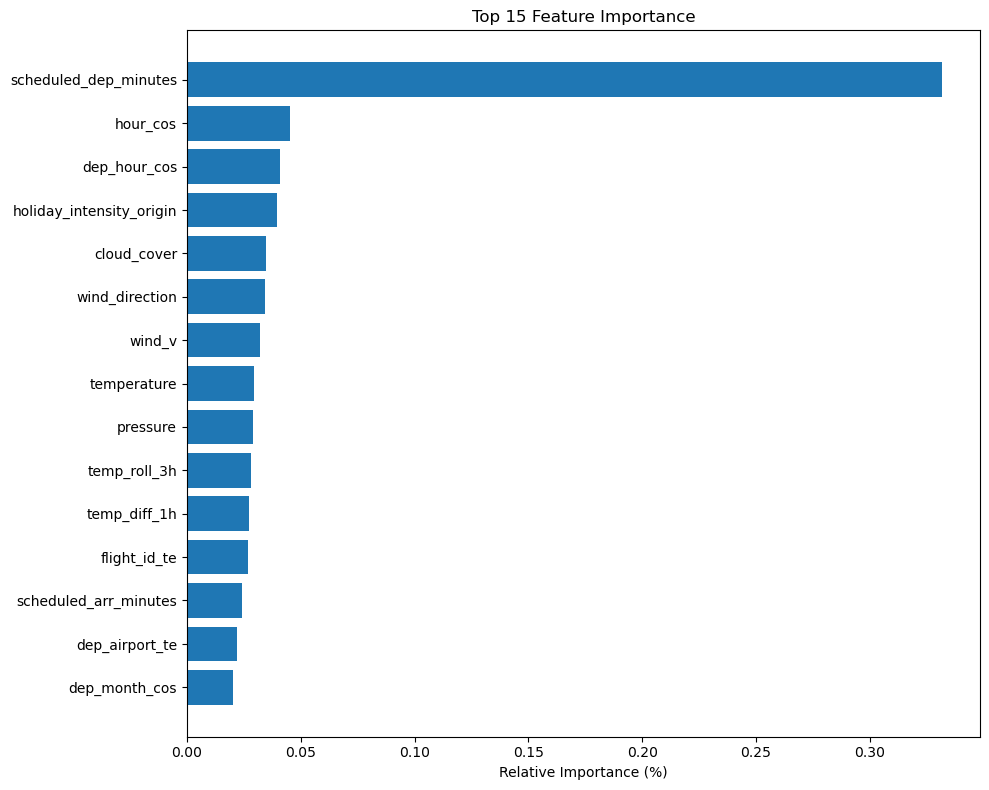

In [ ]:
# Plot variable importance

dep_varimp = best_dep_model.varimp(use_pandas=True)
arr_varimp = best_arr_model.varimp(use_pandas=True)
plt.figure(figsize=(10, 8))
if dep_varimp is not None:
    top_features = dep_varimp.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

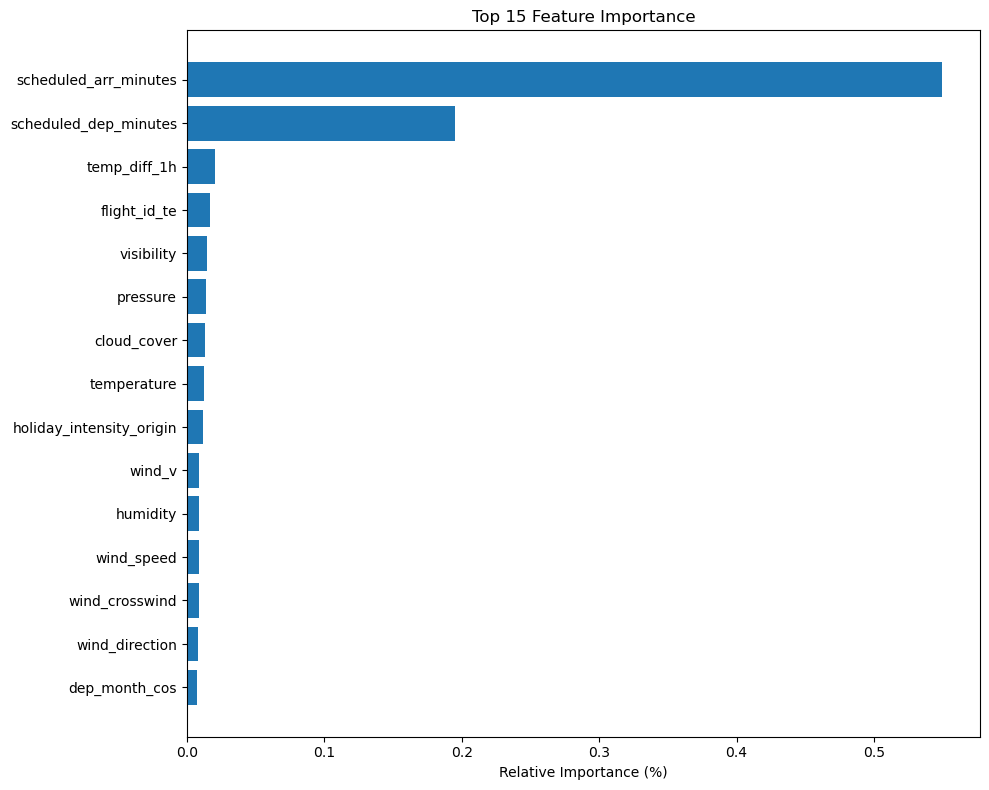

In [ ]:
# Plot variable importance
plt.figure(figsize=(10, 8))
if arr_varimp is not None:
    top_features = arr_varimp.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

=== WEATHER FEATURES IMPACT ANALYSIS ===

=== DEPARTURE MODEL - Weather Feature Importance ===
Top weather features for departure prediction:
          variable  percentage
1         hour_cos    0.045451
4      cloud_cover    0.034606
5   wind_direction    0.034357
6           wind_v    0.032094
7      temperature    0.029482
8         pressure    0.028907
9     temp_roll_3h    0.027969
10    temp_diff_1h    0.027080
15   wind_category    0.019953
16   wind_headwind    0.018044
Total weather features contribution: 0.39%

=== ARRIVAL MODEL - Weather Feature Importance ===
Top weather features for arrival prediction:
          variable  percentage
2     temp_diff_1h    0.020126
4       visibility    0.014315
5         pressure    0.013623
6      cloud_cover    0.012940
7      temperature    0.012779
9           wind_v    0.009161
10        humidity    0.008984
11      wind_speed    0.008831
12  wind_crosswind    0.008505
13  wind_direction    0.008070
Total weather features contribution:

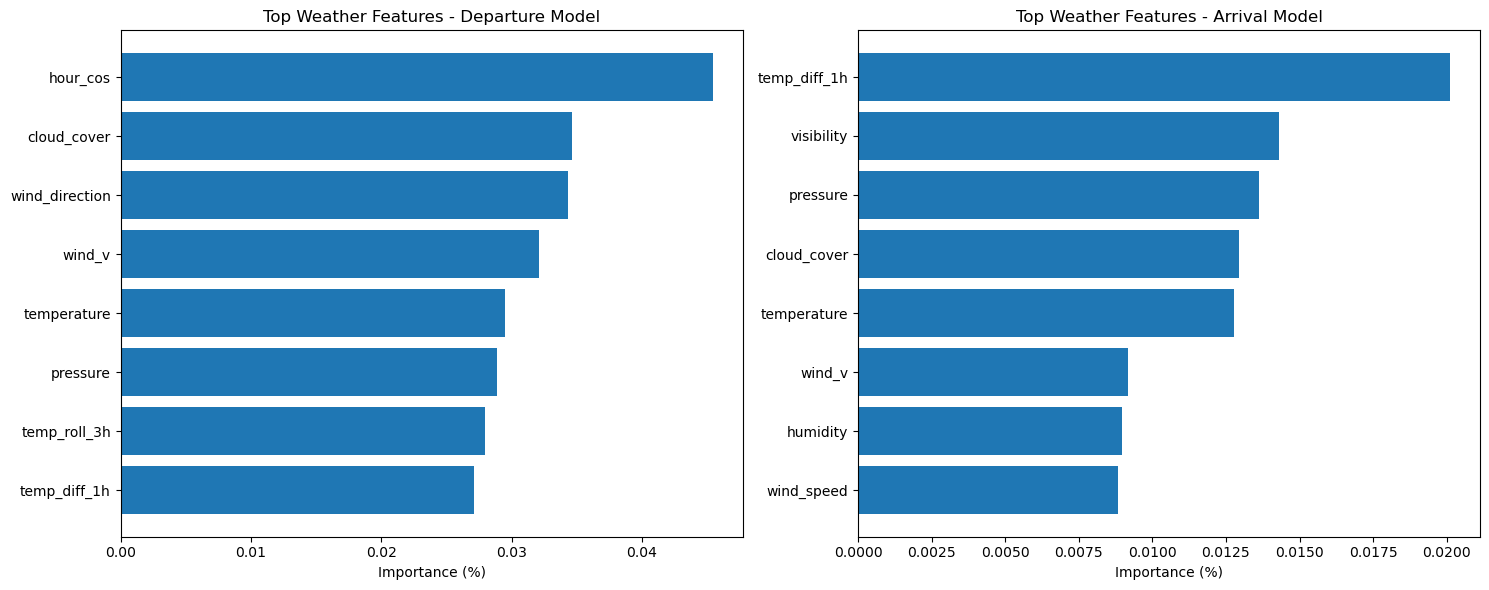


=== WEATHER INTEGRATION SUMMARY ===
Total features with weather: 49
Weather-related features available: 23
Dataset coverage with weather: 90.0%


In [ ]:
# Weather Features Impact Analysis
print("=== WEATHER FEATURES IMPACT ANALYSIS ===")

# Analyze weather features in variable importance
weather_related_features = [
    'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 
    'wind_speed', 'wind_direction', 'visibility', 'temp_diff_1h', 'temp_roll_3h',
    'precip_roll_3h', 'wind_u', 'wind_v', 'wind_headwind', 'wind_crosswind',
    'temp_category', 'precip_category', 'wind_category', 'hour_sin', 'hour_cos',
    'dow_sin', 'dow_cos', 'is_weekend'
]

print("\n=== DEPARTURE MODEL - Weather Feature Importance ===")
if dep_varimp is not None and not dep_varimp.empty:
    weather_importance_dep = dep_varimp[dep_varimp['variable'].isin(weather_related_features)]
    if not weather_importance_dep.empty:
        print(f"Top weather features for departure prediction:")
        print(weather_importance_dep.head(10)[['variable', 'percentage']])
        total_weather_importance = weather_importance_dep['percentage'].sum()
        print(f"Total weather features contribution: {total_weather_importance:.2f}%")
    else:
        print("No weather features found in top importance")

print("\n=== ARRIVAL MODEL - Weather Feature Importance ===")
if arr_varimp is not None and not arr_varimp.empty:
    weather_importance_arr = arr_varimp[arr_varimp['variable'].isin(weather_related_features)]
    if not weather_importance_arr.empty:
        print(f"Top weather features for arrival prediction:")
        print(weather_importance_arr.head(10)[['variable', 'percentage']])
        total_weather_importance = weather_importance_arr['percentage'].sum()
        print(f"Total weather features contribution: {total_weather_importance:.2f}%")
    else:
        print("No weather features found in top importance")

# Create weather feature importance visualization
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Departure model weather features
if 'weather_importance_dep' in locals() and not weather_importance_dep.empty:
    top_weather_dep = weather_importance_dep.head(8)
    ax1.barh(range(len(top_weather_dep)), top_weather_dep['percentage'])
    ax1.set_yticks(range(len(top_weather_dep)))
    ax1.set_yticklabels(top_weather_dep['variable'])
    ax1.set_xlabel('Importance (%)')
    ax1.set_title('Top Weather Features - Departure Model')
    ax1.invert_yaxis()

# Arrival model weather features  
if 'weather_importance_arr' in locals() and not weather_importance_arr.empty:
    top_weather_arr = weather_importance_arr.head(8)
    ax2.barh(range(len(top_weather_arr)), top_weather_arr['percentage'])
    ax2.set_yticks(range(len(top_weather_arr)))
    ax2.set_yticklabels(top_weather_arr['variable'])
    ax2.set_xlabel('Importance (%)')
    ax2.set_title('Top Weather Features - Arrival Model')
    ax2.invert_yaxis()

plt.tight_layout()
plt.show()

print(f"\n=== WEATHER INTEGRATION SUMMARY ===")
print(f"Total features with weather: {len(feature_columns)}")
print(f"Weather-related features available: {len([f for f in feature_columns if f in weather_related_features])}")
print(f"Dataset coverage with weather: {weather_match_rate:.1f}%")